# Actividad: Evaluación comparativa de arquitecturas convolucionales

Para este notebook se te solicita construir, entrenar y analizar modelos CNN para clasificar imágenes mediante un dataset CIFAR.

**Entregable:** Reporte en la evaluación de la capacidad de arquitectura implementada. Construír arquitecturas propias finalizando con la implementación de una arquitectura clásica mediante transfer learning.


## Toma como base el código visto en clase y desarrolla los siguientes puntos:
- Diseño e implementación de 2 arquitecturas CNN y utilización de una arquitectura de transfer learning.

- Buen uso de data augmentation y regularización.

- Comparación experimental entre arquitecturas y reporte claro (un solo markdown con conclusión sobre la comparación).





In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2

tf.random.set_seed(42)
np.random.seed(42)

# Datos CIFAR-10: 10 clases, imágenes 32x32 RGB
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.flatten(), y_test.flatten()
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")
NUM_CLASSES = 10
INPUT_SHAPE = (32, 32, 3)

# Data augmentation (solo activo durante entrenamiento)
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 625s 4us/step


## Definiciones de modelos

In [2]:
def build_cnn_simple():
    # CNN básica: 2 bloques conv + dropout
    inp = keras.Input(INPUT_SHAPE)
    x = data_augmentation(inp)
    x = layers.Rescaling(1./255)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="cnn_simple")


def build_cnn_profunda():
    # CNN estilo VGG con BatchNorm, Dropout y L2
    reg = keras.regularizers.l2(1e-4)
    inp = keras.Input(INPUT_SHAPE)
    x = data_augmentation(inp)
    x = layers.Rescaling(1./255)(x)
    for filtros, drop in [(32, 0.2), (64, 0.3), (128, 0.4)]:
        for _ in range(2):
            x = layers.Conv2D(filtros, 3, padding="same", kernel_regularizer=reg)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(drop)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="cnn_profunda")


def build_transfer_mobilenet():
    # MobileNetV2 preentrenada en ImageNet, base congelada
    base = MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = keras.Input(INPUT_SHAPE)
    x = data_augmentation(inp)
    x = layers.Resizing(96, 96)(x)
    x = keras.applications.mobilenet_v2.preprocess_input(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="mobilenetv2_transfer")


for m in (build_cnn_simple(), build_cnn_profunda(), build_transfer_mobilenet()):
    m.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "cnn_simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

... (6 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Entrenamiento de modelos.

In [3]:
EPOCHS = 15
BATCH = 128
histories, resultados = {}, []

for builder in (build_cnn_simple, build_cnn_profunda, build_transfer_mobilenet):
    model = builder()
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    callbacks = [
        keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_accuracy"),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2),
    ]
    h = model.fit(x_train, y_train, validation_split=0.1, epochs=EPOCHS,
                  batch_size=BATCH, callbacks=callbacks, verbose=2)
    loss, acc = model.evaluate(x_test, y_test, verbose=0)
    histories[model.name] = h.history
    resultados.append({"modelo": model.name, "params": model.count_params(),
                       "test_loss": loss, "test_acc": acc,
                       "epocas": len(h.history["loss"])})


Epoch 1/15
352/352 - 9s - 26ms/step - accuracy: 0.3222 - loss: 1.8533 - val_accuracy: 0.4288 - val_loss: 1.5752 - learning_rate: 0.0010
Epoch 2/15
352/352 - 8s - 22ms/step - accuracy: 0.4218 - loss: 1.5899 - val_accuracy: 0.4888 - val_loss: 1.4003 - learning_rate: 0.0010
Epoch 3/15
352/352 - 7s - 21ms/step - accuracy: 0.4572 - loss: 1.4965 - val_accuracy: 0.5298 - val_loss: 1.2956 - learning_rate: 0.0010
Epoch 4/15
352/352 - 8s - 22ms/step - accuracy: 0.4756 - loss: 1.4492 - val_accuracy: 0.5304 - val_loss: 1.2787 - learning_rate: 0.0010
Epoch 5/15
352/352 - 9s - 25ms/step - accuracy: 0.4950 - loss: 1.4055 - val_accuracy: 0.5622 - val_loss: 1.2236 - learning_rate: 0.0010
Epoch 6/15
352/352 - 8s - 24ms/step - accuracy: 0.5081 - loss: 1.3656 - val_accuracy: 0.5664 - val_loss: 1.2010 - learning_rate: 0.0010
Epoch 7/15
352/352 - 8s - 23ms/step - accuracy: 0.5210 - loss: 1.3477 - val_accuracy: 0.5870 - val_loss: 1.1509 - learning_rate: 0.0010
Epoch 8/15
352/352 - 8s - 21ms/step - accuracy: 

## Estadística y gráficos

,params,test_loss,test_acc,epocas
modelo,,,,
cnn_simple,545098,1.071276,0.6277,15
cnn_profunda,306602,0.904292,0.7155,15
mobilenetv2_transfer,2270794,0.597350,0.7967,10


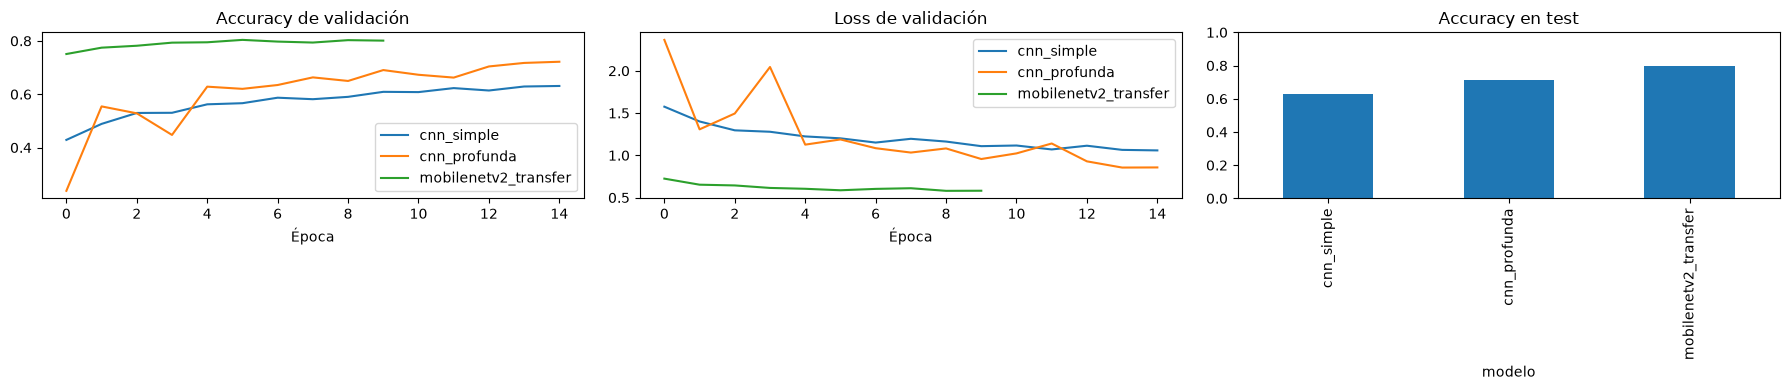

In [4]:
df = pd.DataFrame(resultados).set_index("modelo")
display(df)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for name, h in histories.items():
    axes[0].plot(h["val_accuracy"], label=name)
    axes[1].plot(h["val_loss"], label=name)
axes[0].set_title("Accuracy de validación"); axes[1].set_title("Loss de validación")
for a in axes[:2]:
    a.set_xlabel("Época"); a.legend()
df["test_acc"].plot.bar(ax=axes[2], title="Accuracy en test", ylim=(0, 1))
plt.tight_layout(); plt.show()


# Conclusiones

Resultados en test (CIFAR-10, con data augmentation, early stopping y ReduceLROnPlateau):

| Modelo | Parámetros | Accuracy test | Loss test |
|---|---|---|---|
| CNN simple (2 conv + dropout) | 545,098 | 62.8 % | 1.071 |
| CNN profunda (6 conv + BatchNorm + Dropout + L2) | 306,602 | 71.6 % | 0.904 |
| MobileNetV2 (transfer learning, base congelada) | 2,270,794 (12,810 entrenables) | **79.7 %** | **0.597** |

**¿Cuál fue el mejor?** MobileNetV2 con transfer learning. Con solo 12,810 parámetros entrenables y menos épocas (10, por early stopping) superó a ambas CNN propias, y desde la primera época ya tenía ~75 % de accuracy de validación, porque sus filtros ya aprendieron bordes, texturas y formas en ImageNet.

**¿Por qué?** Las CNN propias parten de cero y con solo 45 mil imágenes de 32x32 les cuesta aprender características generales. Entre ellas, la CNN profunda ganó a la simple (+9 puntos) con menos parámetros: más capas convolucionales extraen mejores características, y BatchNorm, Dropout y L2 estabilizan el entrenamiento. La CNN simple concentra casi todos sus parámetros en la capa densa (524 mil), que es poco eficiente. No hubo sobreajuste fuerte en ningún modelo: el accuracy de validación y el de test fueron parecidos y la augmentation actuó como regularizador.

**¿Qué mejoraría?**
- Entrenar más épocas las CNN propias; todavía mejoraban al terminar las 15 (la CNN profunda sobre todo).
- Aplicar *fine-tuning*: descongelar los últimos bloques de MobileNetV2 con una tasa de aprendizaje muy baja (por ejemplo 1e-5), lo que normalmente lleva a más de 90 %.
- Probar imágenes de mayor resolución para el modelo preentrenado (el 96x96 es un reescalado de 32x32), y otras arquitecturas como ResNet50 o EfficientNet.
- Añadir bloques residuales a la CNN profunda y técnicas de augmentation más fuertes (CutMix/MixUp), además de un scheduler de aprendizaje tipo cosine.
- Limitaciones: se hizo una sola corrida por modelo; repetir con varias semillas daría una comparación más confiable.


# Anexo: ¿Qué significa cada parte de las arquitecturas?

Los diagramas de flujo de cada arquitectura están en [README.md](README.md).

## Glosario de componentes

| Componente | Qué hace | Por qué se usa aquí |
|---|---|---|
| **Rescaling(1/255)** | Convierte los píxeles de 0-255 a 0-1. | Redes entrenan mejor con entradas pequeñas. |
| **Data augmentation** (`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomTranslation`) | Genera variaciones aleatorias de cada imagen (espejo, giro, zoom, desplazamiento) solo al entrenar. | Es como tener más datos; evita memorizar y reduce el sobreajuste. |
| **Conv2D** | Desliza filtros (ej. 3x3) sobre la imagen para detectar patrones: bordes, texturas, formas. | Es el "ojo" de la red; más filtros = más patrones distintos. |
| **padding="same"** | Rellena los bordes con ceros para que la salida conserve el tamaño. | Evita perder información en las orillas. |
| **ReLU** | Activación: deja pasar valores positivos y vuelve 0 los negativos. | Aporta no linealidad y es rápida de calcular. |
| **MaxPooling2D** | Reduce la imagen a la mitad quedándose con el valor máximo de cada ventana 2x2. | Menos cómputo y algo de tolerancia a pequeños desplazamientos. |
| **BatchNormalization** | Normaliza las salidas de cada capa por lote (media 0, varianza 1). | Entrenamiento más estable y rápido; permite tasas de aprendizaje mayores. |
| **Dropout(p)** | Apaga al azar una fracción `p` de neuronas en cada paso de entrenamiento. | Obliga a la red a no depender de neuronas concretas: regularización. |
| **L2 (kernel_regularizer)** | Suma a la pérdida un castigo proporcional al cuadrado de los pesos (aquí 1e-4). | Mantiene los pesos pequeños y el modelo más simple; reduce sobreajuste. |
| **Flatten** | Convierte el mapa de características 2D en un vector 1D. | Prepara los datos para la capa densa. |
| **GlobalAveragePooling2D** | Promedia cada mapa de características a un solo número. | Reemplaza a Flatten con muchos menos parámetros y menos sobreajuste. |
| **Dense** | Capa totalmente conectada: cada neurona recibe todas las entradas. | Combina las características para decidir la clase. |
| **Softmax** | Convierte las 10 salidas en probabilidades que suman 1. | Da la probabilidad de cada clase de CIFAR-10. |
| **Resizing(96, 96)** | Agranda la imagen de 32x32 a 96x96. | MobileNetV2 preentrenada funciona mejor con imágenes más grandes. |
| **preprocess_input** | Escala los píxeles al rango [-1, 1] que espera MobileNetV2. | Debe coincidir con el preprocesamiento original de ImageNet. |
| **Transfer learning / `trainable=False`** | Reutiliza una red preentrenada en ImageNet y congela sus pesos; solo se entrena la cabeza nueva. | Aprovecha conocimiento previo; entrena rápido con pocos datos. |
| **Adam (lr=1e-3)** | Optimizador que ajusta la tasa de aprendizaje por parámetro. | Converge rápido sin mucho ajuste. |
| **EarlyStopping** | Detiene el entrenamiento si `val_accuracy` no mejora en 4 épocas y restaura los mejores pesos. | Evita sobreentrenar. |
| **ReduceLROnPlateau** | Reduce a la mitad la tasa de aprendizaje si la validación se estanca. | Permite un ajuste más fino al final. |
| **sparse_categorical_crossentropy** | Pérdida para clasificación multiclase con etiquetas enteras (0-9). | Etiquetas de CIFAR-10 son números, no one-hot. |

## 1. CNN simple (`cnn_simple`)

Arquitectura mínima: dos bloques de convolución + pooling y una capa densa con Dropout del 50 %.
- Conv(32) y Conv(64): aprenden patrones simples y luego combinados.
- Dense(128) + Dropout(0.5): clasifica y se regulariza (la mayoría de sus parámetros están aquí).

## 2. CNN profunda (`cnn_profunda`)

Estilo VGG: tres bloques de dos convoluciones cada uno (32, 64, 128 filtros). Cada convolución va seguida de BatchNorm y ReLU; cada bloque termina con MaxPooling y Dropout creciente (0.2, 0.3, 0.4). Usa regularización L2 en convoluciones y en la capa densa, y `GlobalAveragePooling2D` en lugar de Flatten.

## 3. MobileNetV2 con transfer learning (`mobilenetv2_transfer`)

Se reutiliza MobileNetV2 (entrenada en ImageNet) como extractor de características congelado. Solo se entrena la cabeza final (Dropout 0.3 + Dense 10), es decir, 12,810 parámetros de 2.27 millones. MobileNetV2 usa bloques *inverted residual* con convoluciones separables en profundidad, que son muy eficientes.
